In [ ]:
import os
import zipfile
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report



In [ ]:
zip_path="/content/Plant_Disease_Workshop (1).zip"
extract_path="/content"
with zipfile.ZipFile(zip_path,"r") as zip_ref:
  zip_ref.extractall(extract_path)
print("Dataset Extracted Successfully!!")

Dataset Extracted Successfully!!


In [ ]:
print(os.listdir("/content"))

['.config', 'Plant_Disease_Workshop', 'Plant_Disease_Workshop (1).zip', 'sample_data']


In [ ]:
dataset_path="/content/Plant_Disease_Workshop"
print(os.listdir(dataset_path))

['val', 'train']


In [ ]:
dataset_path="/content/Plant_Disease_Workshop/train"
print(os.listdir(dataset_path))

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


In [ ]:
dataset_path="/content/Plant_Disease_Workshop/val"
print(os.listdir(dataset_path))

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


In [ ]:
train_path = "/content/Plant_Disease_Workshop/train"
val_path = "/content/Plant_Disease_Workshop/val"

print("==================Train Dataset==================")

for folder in os.listdir(train_path):
    folder_path=os.path.join(train_path,folder)
    print(folder,":",len(os.listdir(folder_path)),"images")


print("\n==================Val Dataset==================\n")

for folder in os.listdir(val_path):
    folder_path=os.path.join(val_path,folder)
    print(folder,":",len(os.listdir(folder_path)),"images")

==================Train Dataset==================
Potato___Early_blight : 800 images
Potato___Late_blight : 800 images
Potato___healthy : 121 images

==================Val Dataset==================

Potato___Early_blight : 200 images
Potato___Late_blight : 200 images
Potato___healthy : 31 images


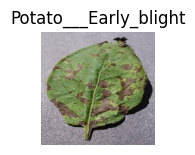

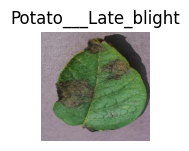

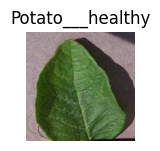

In [ ]:
plt.figure(figsize=(15,5))
classes = os.listdir(train_path)
for i,folder in enumerate(classes):
    image_name = os.listdir(os.path.join(train_path,folder))[0]
    image_path = os.path.join(train_path,folder,image_name)
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
    plt.subplot(3,3,i+1)
    plt.imshow(image)
    plt.title(folder)
    plt.axis("off")
    plt.show()


In [ ]:
train_path="/content/Plant_Disease_Workshop/train"
val_path="/content/Plant_Disease_Workshop/val"
image_size=(64,64)

In [ ]:
X_train=[]
y_train=[]

X_val=[]
y_val=[]


In [ ]:
for label in os.listdir(train_path):
  folder_path = os.path.join(train_path, label)
  for image_name in os.listdir(folder_path):
    image_path = os.path.join(folder_path, image_name)
    image = cv2.imread(image_path)
    image = cv2.resize(image, image_size)
    X_train.append(image)
    y_train.append(label)
print("Validation Image Loaded Successfully")

Validation Image Loaded Successfully


In [ ]:
for label in os.listdir(val_path):
  folder_path = os.path.join(val_path, label)
  for image_name in os.listdir(folder_path):
    image_path = os.path.join(folder_path, image_name)
    image = cv2.imread(image_path)
    image = cv2.resize(image, image_size)
    X_val.append(image)
    y_val.append(label)
print("Validation Image Loaded Successfully")

Validation Image Loaded Successfully


In [ ]:
print("Trainning images:",len(X_train))
print("Validation images:",len(y_train))

print("Trainning images:",len(X_val))
print("Validation images:",len(y_val))

Trainning images: 1721
Validation images: 1721
Trainning images: 431
Validation images: 431


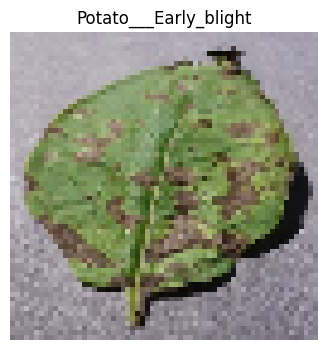

In [ ]:
plt.figure(figsize=(4,4))
plt.imshow(cv2.cvtColor(X_train[0],cv2.COLOR_BGR2RGB))
plt.title(y_train[0])
plt.axis("off")
plt.show()

In [ ]:
X_train=np.array(X_train)
X_val=np.array(X_val)
y_train=np.array(y_train)

y_val=np.array(y_val)
print("converted successfully!")

converted successfully!


In [ ]:
print("Trainning Shape:",X_train.shape)
print("Validation Shape:",X_val.shape)

Trainning Shape: (1721, 64, 64, 3)
Validation Shape: (431, 64, 64, 3)


In [ ]:
X_train=X_train.reshape(X_train.shape[0],-1)
X_val=X_val.reshape(X_val.shape[0],-1)
print("Images Reshaped Successfully")

Images Reshaped Successfully


In [ ]:
print("Trainning Shape:",X_train.shape)
print("Validation Shape:",X_val.shape)

Trainning Shape: (1721, 12288)
Validation Shape: (431, 12288)


In [ ]:
X_train=X_train/255.0
X_val=X_val/255.0
print("Normalizaton Completed!")

Normalizaton Completed!


In [ ]:
encoder= LabelEncoder()
y_train = encoder.fit_transform(y_train)
y_val=encoder.transform(y_val)

print("Label encoded Successfully")

Label encoded Successfully


In [ ]:
print("encoded classes:")
print(encoder.classes_)

print()

print("First 10 Labels:")
print(y_train[:10])

encoded classes:
['Potato___Early_blight' 'Potato___Late_blight' 'Potato___healthy']

First 10 Labels:
[0 0 0 0 0 0 0 0 0 0]


In [ ]:
print("Trainning Featurs Shape:",X_train.shape)
print("Trainning Labels Shape:",y_train.shape)
print()
print("Validation Featurs Shape:",X_val.shape)
print("Validation Labels Shape:",y_val.shape)



Trainning Featurs Shape: (1721, 12288)
Trainning Labels Shape: (1721,)

Validation Featurs Shape: (431, 12288)
Validation Labels Shape: (431,)


In [ ]:
Logistic_model=LogisticRegression(max_iter=1000)
print("Logistic Regression model created Successfully!")

Logistic Regression model created Successfully!


In [ ]:
Logistic_model.fit(X_train,y_train)
print("Model Trainning Completed")

Model Trainning Completed


In [ ]:
y_pred= Logistic_model.predict(X_val)
print("Prediction Completed")

Prediction Completed


In [ ]:
print("Actual Labels:",y_val[:10])
print("Predicted Labels:",y_pred[:10])

Actual Labels: [0 0 0 0 0 0 0 0 0 0]
Predicted Labels: [0 0 0 0 0 0 0 0 0 0]


In [ ]:
acc = accuracy_score(y_val,y_pred)
print("Accuracy:",round(acc * 100,2),"%")

Accuracy: 90.72 %


In [ ]:
cmx = confusion_matrix(y_val,y_pred)
print(cmx)

[[185  15   0]
 [  8 189   3]
 [  0  14  17]]


In [ ]:
print(classification_report(y_val,y_pred,target_names=encoder.classes_))

                       precision    recall  f1-score   support

Potato___Early_blight       0.96      0.93      0.94       200
 Potato___Late_blight       0.87      0.94      0.90       200
     Potato___healthy       0.85      0.55      0.67        31

             accuracy                           0.91       431
            macro avg       0.89      0.81      0.84       431
         weighted avg       0.91      0.91      0.90       431



In [ ]:
predicted_labels = encoder.inverse_transform(y_pred[:10])
print("Predicted Labels of first 10 :",predicted_labels)

Predicted Labels of first 10 : ['Potato___Early_blight' 'Potato___Early_blight' 'Potato___Early_blight'
 'Potato___Early_blight' 'Potato___Early_blight' 'Potato___Early_blight'
 'Potato___Early_blight' 'Potato___Early_blight' 'Potato___Early_blight'
 'Potato___Early_blight']


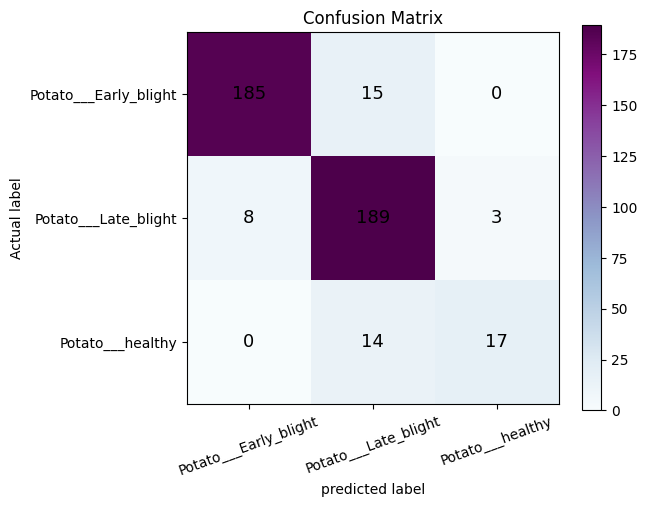

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,5))
plt.imshow(cmx,cmap="BuPu")
plt.title("Confusion Matrix")
plt.colorbar()
plt.xticks(range(3),encoder.classes_,rotation=20)
plt.yticks(range(3),encoder.classes_)

for i in range(len(cmx)):
  for j in range(len(cmx)):
    plt.text(j,i,cmx[i][j],
             ha="center",
             va="center",
             color="black",
             fontsize=13)
plt.xlabel("predicted label")
plt.ylabel("Actual label")
plt.show()

In [ ]:
#Logistics
print("="*40)
print("Logistic Regression Completed Successfully!!")
print("="*40)

print("Accuracy:",round(acc * 100,2),"%")


Logistic Regression Completed Successfully!!
Accuracy: 90.72 %


In [ ]:
svm_model=SVC(kernel="linear")
print("SVM model created Successfully!")

SVM model created Successfully!


In [ ]:
svm_model.fit(X_train,y_train)
print("Model Trainning Completed")

Model Trainning Completed


In [ ]:
svm_pred=svm_model.predict(X_val)
print("Prediction Completed")

Prediction Completed


In [ ]:
svm_acc = accuracy_score(y_val,svm_pred)
print("Accuracy:",round(svm_acc * 100,2),"%")

Accuracy: 91.18 %


In [ ]:
svm_cm = confusion_matrix(y_val,svm_pred)
print(cmx)

[[185  15   0]
 [  8 189   3]
 [  0  14  17]]


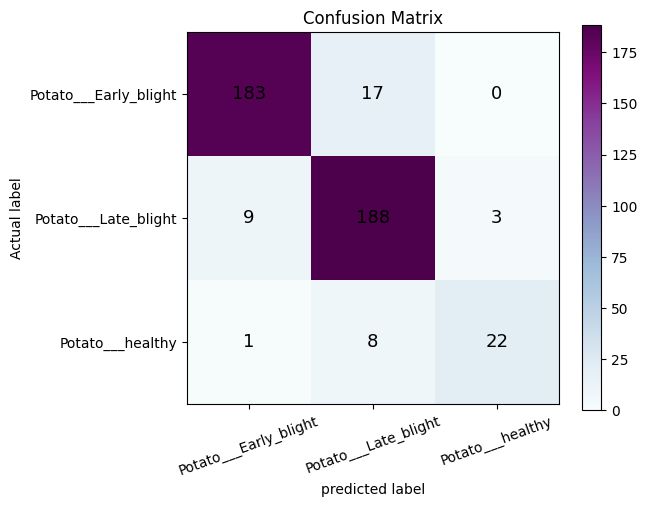

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,5))
plt.imshow(svm_cm,cmap="BuPu")
plt.title("Confusion Matrix")
plt.colorbar()
plt.xticks(range(3),encoder.classes_,rotation=20)
plt.yticks(range(3),encoder.classes_)

for i in range(len(svm_cm)):
  for j in range(len(svm_cm)):
    plt.text(j,i,svm_cm[i][j],
             ha="center",
             va="center",
             color="black",
             fontsize=13)
plt.xlabel("predicted label")
plt.ylabel("Actual label")
plt.show()

In [ ]:

print("="*40)
print("SVM Completed Successfully!!")
print("="*40)

print("Accuracy:",round(svm_acc* 100,2),"%")

SVM Completed Successfully!!
Accuracy: 91.18 %


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving images.jpg to images.jpg


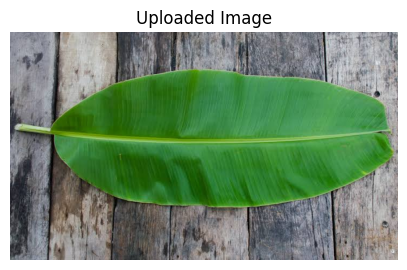

In [ ]:
image_name = list(uploaded.keys())[0]
image = cv2.imread(image_name)
image_rgb=cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
plt.figure(figsize=(5,5))
plt.imshow(image_rgb)
plt.title("Uploaded Image")
plt.axis("off")
plt.show()

In [ ]:
test_image = cv2.resize(image,(64,64))
test_image = test_image.reshape(1,-1)
test_image = test_image/255.0
print("Image Preprocessed Successfully!")

Image Preprocessed Successfully!


In [ ]:
prediction = svm_model.predict(test_image)
predicted_disease = encoder.inverse_transform(prediction)
print("Predicted Disease:",predicted_disease[0])

Predicted Disease: Potato___healthy


In [ ]:
if predicted_disease[0] == "Potato___Early_blight":
  print("The Disease is Potato___Early_blight")
  print("remove and throw")
elif predicted_disease[0] == "Potato___Late_blight":
  print("The Disease is Potato___Late_blight")
  print("Advice:Improve Drainage , avoid over head watring and use proper fertilizer")
else:
  print("The Disease is Potato___healthy")
  print("Advice:No Action Required")

The Disease is Potato___healthy
Advice:No Action Required


In [ ]:
comparison = {
    "Model": ["Logistic Regression", "SVM"],
    "Accuracy": [round(acc * 100, 2), round(svm_acc * 100, 2)]
}
import pandas as pd

comparison_df = pd.DataFrame(comparison)
(comparison_df)


,Model,Accuracy
0,Logistic Regression,90.72
1,SVM,91.18


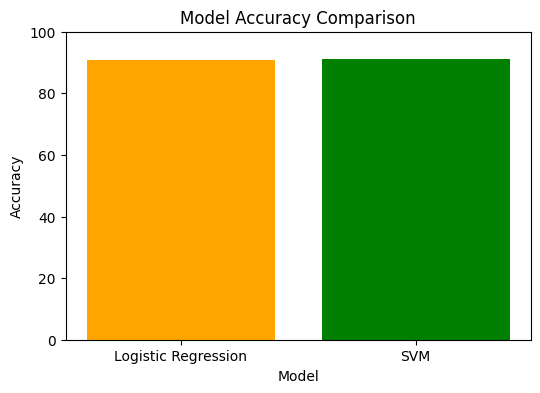

In [ ]:
plt.figure(figsize=(6,4))
color=['orange','green']
plt.bar(comparison_df["Model"],comparison_df["Accuracy"],color=color)
plt.ylim(0,100)
plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.show()

In [ ]:
if svm_acc > acc:
  print("SVM Model is better than Logistic Regression")
else:
  print("Logistic Regression Model is better than SVM")

SVM Model is better than Logistic Regression
